# K-medoids (heuristic)

In [2]:
import time
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import euclidean_distances
from sklearn_extra.cluster._k_medoids import KMedoids

## Data

In [3]:
iris = load_iris()
X = iris.data
y = iris.target

## K-medoids (heuristic)

In [ ]:
%%time
# start_time = time.perf_counter()

kmedoids = KMedoids(n_clusters=3, random_state=42)
k

y_pred = kmedoids.labels_
medoid_indices = kmedoids.medoid_indices_

# end_time = time.perf_counter()
# print(f"Temps de calcul K-Medoids : {end_time - start_time:.6f} secondes")

CPU times: user 16.8 ms, sys: 3.75 ms, total: 20.5 ms
Wall time: 20.4 ms


Here is the visualisation (after a PCA to have a two-dimensional representation):

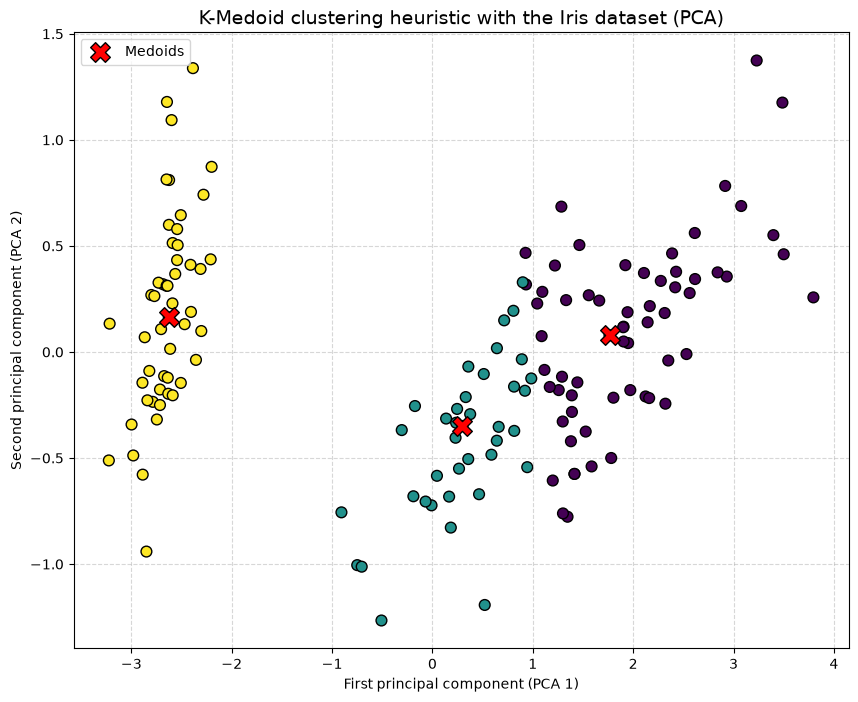

In [5]:

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)


plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    X_2d[:, 0], X_2d[:, 1], c=y_pred, cmap='viridis', s=60, edgecolor='k', zorder=2
)

plt.scatter(
    X_2d[medoid_indices, 0],
    X_2d[medoid_indices, 1],
    c='red',
    marker='X',
    s=200,
    edgecolor='black',
    label='Medoids',
    zorder=3,
)

plt.title(
    "K-Medoid clustering heuristic with the Iris dataset (PCA)", fontsize=14
)
plt.xlabel("First principal component (PCA 1)")
plt.ylabel("Second principal component (PCA 2)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig("iris_heuristic_kmedoids.png")
plt.show()